# 02 · Acquisition: `acq` and `pe`

The PIC32AK samples the RX chain at 25 Msps (40 ns per sample) and sends 4095 samples to the RP, which prints them
as one number per line after a `# acq …` header. `acq` captures without firing the pulser. `pe` (pulse-echo) fires
the pulser exactly when the capture starts. A transducer on the board gives echoes.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "library"))   # the minus package (or: pip install -e python/library)
import warnings
warnings.filterwarnings("ignore", message="Unable to import Axes3D")   # harmless on mixed matplotlib installs
import numpy as np
import matplotlib.pyplot as plt
from minus import Minus, MinusError
import minus
print("library", minus.__version__, "written for firmware", minus.FIRMWARE)

library 1.1.9 written for firmware {'rp': {'name': 'minus-rp2354', 'version': '1.1.9'}, 'pic': {'name': 'minus-pic32', 'version': '1.1.6'}, 'proto': 15}


In [2]:
dev = Minus()
dev.version().version, dev.pic_ident().version

('1.1.9', '1.1.6')

## 1. `acq`: a capture without a pulse (noise floor)

`acq(div, samc, in_, navg)`: `div` = trigger period in 5 ns counts (4 → 25 Msps), `samc` = ADC sampling time,
`in_` = which node (25 = the filtered RX output, see `minus.INPUTS`), `navg` = conversions summed per sample.
The PIC remembers these settings between calls.

In [3]:
minus.INPUTS

{25: 'AD2AN9: OA2 output after the anti-alias filter (default)',
 17: 'AD2AN1: OA2 output before the filter',
 0: 'AD1AN0: OA1 output',
 1: 'AD1AN1: OA1 input = LNA output',
 19: 'AD2AN3: DACOUT1 (PIC DAC test signal, U9 pin 3)',
 7: 'AD1AN7: DACOUT1 on ADC1'}

In [4]:
a = dev.acq(4, 0, 25, 1)
dev.last.show()

>>> acq 4 0 25 1
<<< # acq n=4095 fill=164.6us fs=24.87Msps rp_fill=163us (RDY window timed by the RP crystal) trigger div 4; in=25 AD2AN9 (PIC32_ADC: OA2OUT after the R67/C86/R68/C87 filter, board 3); navg=1 (12-bit unsigned) link=spi@12.50MHz xfer=5715us
<<< # b64 8190
<<< yAf5B+QH3gfJB/MH3AfdB8EH9QfdB94HwwfzB9sH3AfFB/AH2gffB8UH9AfaB94Hxgf1B9kH3AfK
<<< B/cH4AfhB8EH8AfdB9sHwQf4B90H3gfAB/YH2QfcB8UH9wfaB+MHyAfzB9cH3gfHB/IH2QfgB8kH
<<< 9AfhB9kHwAfxB9sH2wfIB/MH3gfaB8QH8AfbB9YHwwfxB+EH2gfHB/EH2gfYB8UH8wfcB+EHxQf3
<<< B9oH1wfGB/MH3QfhB8sH+wfeB+IHwwf8B9sH4AfLB/0H3gfkB8gH9wfhB+QHyAf7B+MH5gfHB/kH
<<< ... (134 more lines) ...
<<< 3QfaB9gH4QfeB98H3gfnB94H3QfeB+AH3AfcB98H4gfbB94H3QfiB9oH4wfbB+MH3QflB9oH4wfY
<<< B9wH3gffB9oH3AfmB+EH3wfaB9wH3gfhB9kH3wflB9kH3AfeB9sH2gfdB9wH4gfeB94H3QfhB9kH
<<< 2wfdB+MH2wfeB+UH3gfdB9cH4AfgB94H2QflB+IH3AfdB9sH5QfVB+IH3gfkB9gH4AfbB+EH2Afg
<<< B9wH4wfcB90H3QfeB9UH3wfZB98H2gffB94H4AfVB9sH3gfgB9wH3QfgB+IH2wffB9oH4QfWB+QH
<<< 3AfmB9oH5QfdB98H1wfeB90H4wffB+EH3gfhB9oH3QfhB9w

The header line says how long the capture window took, measured by the PIC (`fill`) and independently by the RP
from the RDY line (`rp_fill`), and the resulting sample rate. The `Capture` object holds the samples as a numpy array:

In [5]:
print(a.n, "samples,", a.fs_msps, "Msps,", round(a.dt_ns, 2), "ns/sample, window", a.fill_us, "us")
print("mean %.1f LSB, std %.2f LSB" % (a.samples.mean(), a.samples.std()))
a.samples[:10]

4095 samples, 24.87 Msps, 40.2 ns/sample, window 164.6 us
mean 2013.7 LSB, std 6.94 LSB


array([1992, 2041, 2020, 2014, 1993, 2035, 2012, 2013, 1985, 2037],
      dtype=uint16)

## 2. `gain`: RX gain

Both op-amp stages share one analog mux: `leg` 0..3 picks Rf = 2.2k/4.7k/6.8k/10k (×3.2/×5.7/×7.8/×11 per
stage, before the LNA). `u1`/`u2` = 1 bypasses that stage (×1).

In [6]:
g = dev.gain(2, 0, 0)
dev.last.show()
g

>>> gain 2 0 0
<<< gain leg 2 (Rf 6.8k) OA1 x7.80 OA2 x7.80 = x60.8 (35.7 dB, + LNA)
    (1 lines, 9 ms)


Gain(leg=2, rf_ohm=6800.0, oa1=7.8, oa1_unity=False, oa2=7.8, oa2_unity=False, total=60.8, total_db=35.7)

## 3. `pe`: one pulse-echo A-line

`pe(hi, lo, in_, dead)`: the pulser drives +5 V for `hi` ns, both FETs off for `dead` ns, then GND for `lo` ns.
Defaults 200 / 500 / 27. The reply is the same as `acq` plus a final `# pulse fired, k shot(s)` line. Sometimes the
ADC locks to a slower pattern, so `pe` re-shoots until the sample clock is uniform; `shots` says how many tries it took.

In [7]:
e = dev.pe(200, 500, 25, 27)
dev.last.show()
print("fired:", e.pulse_fired, "| shots:", e.shots)

>>> pe 200 500 25 27
<<< # acq n=4095 fill=164.6us fs=24.87Msps rp_fill=162us (RDY window timed by the RP crystal) pulse-echo: pulse on RDY rise (+5V 200 / off 27 / GND 500 ns), in=25 AD2AN9 (PIC32_ADC: OA2OUT after the R67/C86/R68/C87 filter, board 3), 40 ns/sample; gain leg 2 (Rf 6.8k) OA1 x7.80 OA2 x7.80 = x60.8 (35.7 dB, + LNA); try 1 link=spi@12.50MHz xfer=5716us
<<< # b64 8190
<<< xwujDm8PlQ+oD5wPuw84CDUCkQAwALoACgc7DREPjg+lD7IPvA+VD6YPnQ+xDtcBeAAcAAsAFAAA
<<< AAAAAAASAAAAAAAAABgADABQAc0IIw+OD60PvA+VD6oPsg+6D5UPpg+uD7YPkA+iD6oPsA+OD5oP
<<< lQ+GD4YPmg+dD4cPdAQqAU0AMwDkADgACQAFABIAAAAAAAAAEQAAAAAAAAASAAAAAAACABAAAAAA
<<< AAEAFAAAAAAADgATAAAAAAACABcAaQAzAVYAGQACAAAACQAfBtMD/gBGABkACADIAFoHsgQ3AVAA
<<< ... (135 more lines) ...
<<< B9kH2AfVB94H6AfpB+YH3wfaB9MH1QfcB+sH3gflB+gH5QfFB8cH0wfWB9MH3wffB98HyQfMB8gH
<<< 1QfNB9IH3AfpB9wH0AfMB9AHywfGB9AH3QfTB9oH1QfQB8sHzgfRB90H1gfeB+QH4gfXB9YH3wfd
<<< B9UH3wfkB+kH5AfeB9UHywfLB88H5wfvB90H2wfXB9YHzAfPB9YH4wfkB94H2gfgB8oHywfOB9cH
<<< 1wfXB9kH4AfHB8

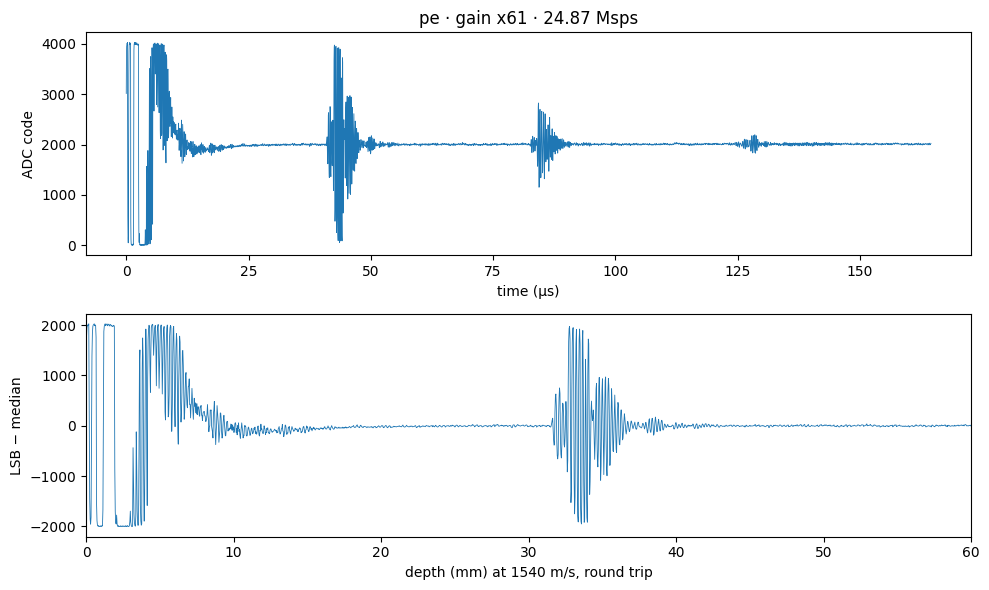

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].plot(e.t_us, e.samples, lw=0.6)
ax[0].set(xlabel="time (µs)", ylabel="ADC code", title=f"pe · gain x{g.total:.0f} · {e.fs_msps} Msps")
ax[1].plot(e.depth_mm(), e.samples.astype(float) - np.median(e.samples), lw=0.6)
ax[1].set(xlabel="depth (mm) at 1540 m/s, round trip", ylabel="LSB − median", xlim=(0, 60))
plt.tight_layout()

## 4. Gain sweep

Same pulse, all four legs. The main bang (the transmit pulse leaking into RX) clips at high gain; the echoes grow.

>>> gain 2 0 0
<<< gain leg 2 (Rf 6.8k) OA1 x7.80 OA2 x7.80 = x60.8 (35.7 dB, + LNA)
    (1 lines, 9 ms)


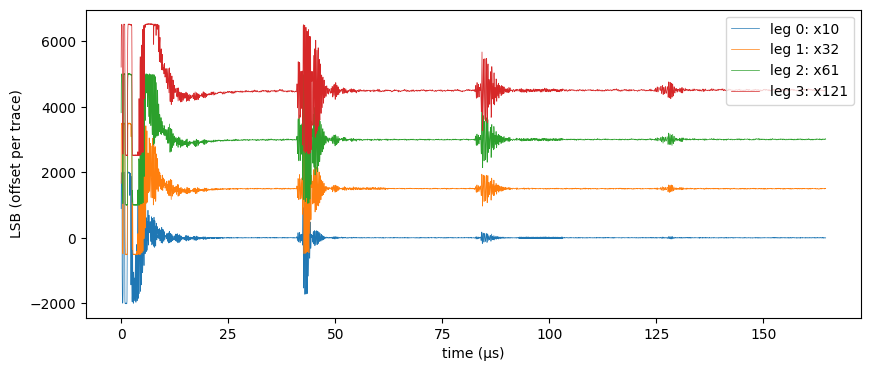

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for leg in range(4):
    gl = dev.gain(leg, 0, 0)
    c = dev.pe()
    ax.plot(c.t_us, c.samples.astype(float) - np.median(c.samples) + 1500 * leg, lw=0.5, label=f"leg {leg}: x{gl.total:.0f}")
ax.set(xlabel="time (µs)", ylabel="LSB (offset per trace)"); ax.legend(loc="upper right")
dev.gain(2, 0, 0); dev.last.show()

## 5. `pc`: pattern correction

The ADC shows a small fixed pattern with a period of 4 samples. The PIC subtracts it (on at boot). `pc` reports
the state and the per-phase offsets it removed from the last capture. Compare the noise with it on and off:

In [10]:
for on in (False, True):
    s = dev.pattern_correction(on); dev.last.show()
    c = dev.acq(4, 0, 25, 1)
    x = c.samples.astype(float)
    phase_means = [x[k::4].mean() - x.mean() for k in range(4)]
    print(f"pc {'on ' if on else 'off'}: std {x.std():.2f} LSB, period-4 means {np.round(phase_means, 2)}")
print(dev.pattern_correction())

>>> pc 0
<<< pattern correction off; last capture offsets (LSB, phase 0..3): +10.19 +8.38 -19.75 +1.19
    (1 lines, 5 ms)
pc off: std 14.57 LSB, period-4 means [-13.41   4.78   8.48   0.15]


>>> pc 1
<<< pattern correction ON; last capture offsets (LSB, phase 0..3): +10.19 +8.38 -19.75 +1.19
    (1 lines, 5 ms)
pc on : std 12.32 LSB, period-4 means [ 0.12 -0.13  0.43 -0.42]
PatternCorrection(on=True, offsets_lsb=(8.19, -2.94, -10.81, 5.56))


### The period-4 correction, step by step, on the host

The same algorithm as the PIC (`acq.c`, `acq_pc_apply`), applied here to a capture taken with the correction **off**, so the
signal before and after can be compared sample by sample (datasheet rev 0.3, §4.7):

1. skip the first 64 samples; 2. mean of each phase k = i mod 4 and the overall mean; 3. offset of phase k = its mean minus
the overall mean (1/16 LSB); 4. subtract its phase's offset from every sample, round, clamp to 0..4095.

phase offsets (LSB): [  3.5      5.8125   7.     -16.3125]
std raw 11.74 LSB -> corrected 6.89 LSB
low phase in the first / second half: [3, 3] (different = a comb slip inside this capture)


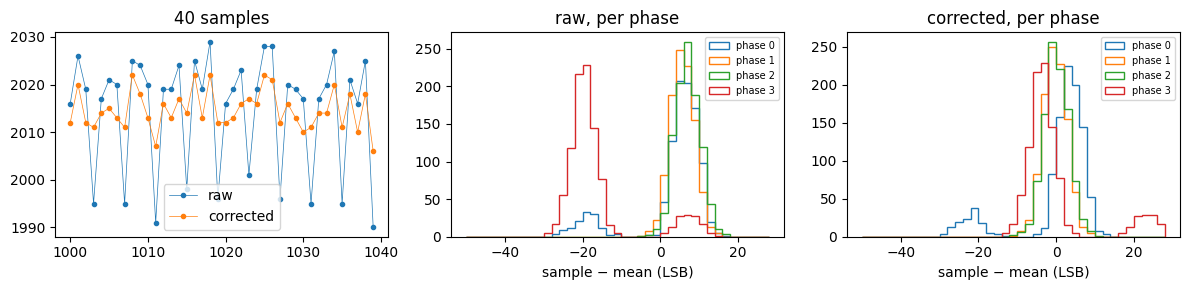

Gain(leg=0, rf_ohm=2200.0, oa1=1.0, oa1_unity=True, oa2=3.2, oa2_unity=False, total=3.2, total_db=10.1)

In [11]:
import numpy as np, matplotlib.pyplot as plt
dev.gain(0, 0, 0); dev.pattern_correction(False)
raw = dev.acq(4, 0, 25, 1).samples.astype(np.int64)
dev.pattern_correction(True)

q = raw[64:]; ph = np.arange(64, len(raw)) & 3                       # 1-2: per-phase and overall means
means = np.array([q[ph == k].mean() for k in range(4)])
off16 = np.round((means - q.mean()) * 16).astype(int)                # 3: offsets in 1/16 LSB
cor = np.clip(np.round((raw * 16 - off16[np.arange(len(raw)) & 3]) / 16), 0, 4095)   # 4
print("phase offsets (LSB):", off16 / 16)
print(f"std raw {raw[64:].std():.2f} LSB -> corrected {cor[64:].std():.2f} LSB")
halves = [int(np.argmin([raw[a:b][(np.arange(a, b) & 3) == k].mean() for k in range(4)])) for a, b in ((64, 2048), (2048, 4095))]
print("low phase in the first / second half:", halves, "(different = a comb slip inside this capture)")

fig, ax = plt.subplots(1, 3, figsize=(12, 3))
idx = np.arange(1000, 1040)
ax[0].plot(idx, raw[idx], "o-", ms=3, lw=0.5, label="raw"); ax[0].plot(idx, cor[idx], "o-", ms=3, lw=0.5, label="corrected")
ax[0].set_title("40 samples"); ax[0].legend()
for a_, axx, title in ((raw, ax[1], "raw, per phase"), (cor, ax[2], "corrected, per phase")):
    for k in range(4):
        axx.hist(a_[64:][(np.arange(64, len(a_)) & 3) == k] - a_[64:].mean(), bins=np.arange(-50, 30, 2), histtype="step", label=f"phase {k}")
    axx.set_title(title); axx.set_xlabel("sample − mean (LSB)"); axx.legend(fontsize=7)
plt.tight_layout(); plt.show()
dev.gain(0, 1, 0)

## 6. Averaging several shots

The sample comb's phase relative to the pulse changes from shot to shot, by up to one sample (40 ns; datasheet E3).
Align shots on a strong echo before averaging them, otherwise the echoes smear. Here: cross-correlate each shot
with the first one around the first echo, apply the sub-sample shift in the Fourier domain, then average.

shot lags vs shot 0 (samples): [0.   0.49 1.39 1.15 1.23 1.03 1.62 0.59]


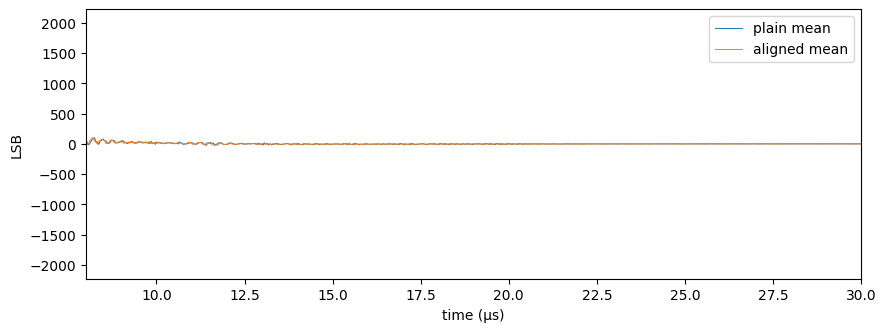

In [12]:
shots = [dev.pe().samples.astype(float) for _ in range(8)]
X = np.array([s - np.median(s) for s in shots])
win = slice(250, 1500)                                     # skip the main bang, keep the first echoes
ref = X[0, win]
def lag_of(x):
    cc = np.correlate(x[win], ref, "full"); k = cc.argmax()
    y0, y1, y2 = cc[k - 1:k + 2]
    return k - (len(ref) - 1) + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2)
lags = np.array([lag_of(x) for x in X])
f = np.fft.rfftfreq(X.shape[1])
aligned = np.array([np.fft.irfft(np.fft.rfft(x) * np.exp(2j * np.pi * f * l), X.shape[1]) for x, l in zip(X, lags)])
print("shot lags vs shot 0 (samples):", np.round(lags, 2))
t = np.arange(X.shape[1]) * e.dt_ns / 1000
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, X.mean(0), lw=0.7, label="plain mean")
ax.plot(t, aligned.mean(0), lw=0.7, label="aligned mean")
ax.set(xlim=(8, 30), xlabel="time (µs)", ylabel="LSB"); ax.legend()

## 7. Processing on the PIC (rp 1.1.9 / pic 1.1.6, proto 15)

Functions that run on the PIC so that less (or nothing) of the A-line crosses the link. The bench transducer is connected:
first echo at ~43 µs, second at ~86 µs, third at ~127 µs (gain ×3.2). Step-by-step descriptions and measurements: datasheet
rev 0.3, §5.

* `tof(thr, blank_ns, in_, ref)` — **time of flight**: pulse, capture, first |x − ref| > thr after the blank (ADC comparator
  armed); one line back.
* `env(dec, shots, in_)` — **envelope**: |x − mean| integrated over `dec` samples, averaged over `shots` pulses.
* `envbp(dec, shots, in_, fc_khz, bw_khz)` — **band-pass envelope**: a Gaussian complex filter around the probe band
  (default 3.3 MHz, 2.5 MHz wide), i.e. an FFT band-pass + Hilbert envelope done as a short filter; it removes the
  out-of-band floor (period-4 residues at 6.2 / 12.4 MHz, the 2.74 MHz line).
* `acqos(4|16, in_, pe)` — ADC **oversampling** (13 / 14-bit) — **not for the 3.3 MHz echo** (it aliases and averages out).

In [13]:
import numpy as np, matplotlib.pyplot as plt
dev.gain(0, 1, 0)
for thr in (30, 60, 150):
    t = dev.tof(thr, 25000, 25)
    print(f"thr {thr:3d}: first crossing {t.t_ns/1000:.2f} us = {t.depth_mm:.1f} mm, peak {t.peak_lsb} LSB, comparator {t.hw_tripped}")

thr  30: first crossing 41.29 us = 31.8 mm, peak 500 LSB, comparator True
thr  60: first crossing 42.38 us = 32.6 mm, peak 512 LSB, comparator True
thr 150: first crossing 42.50 us = 32.7 mm, peak 502 LSB, comparator True


env   x1: first-echo peak   368.1 LSB, floor rms  1.23 ->  49.5 dB
env  x16: first-echo peak   330.6 LSB, floor rms  3.41 ->  39.7 dB
envbp x1: first-echo peak   532.8 LSB, floor rms  0.73 ->  57.3 dB
envbp x16: first-echo peak   468.1 LSB, floor rms  0.69 ->  56.6 dB


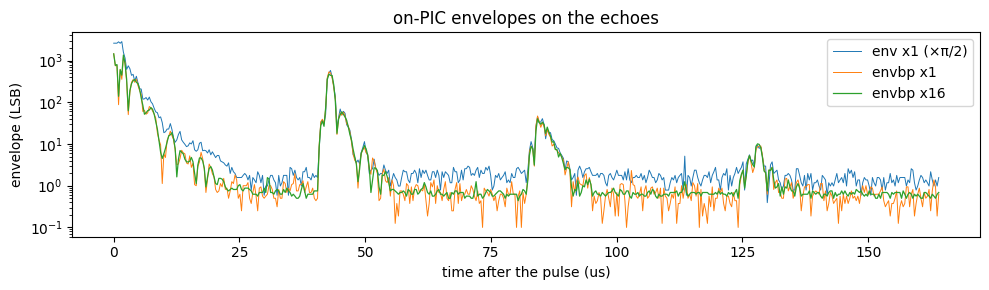

In [14]:
e1, e16 = dev.env(8, 1, 25), dev.env(8, 16, 25)
b1, b16 = dev.envbp(8, 1, 25), dev.envbp(8, 16, 25)
q = (e1.t_us > 55) & (e1.t_us < 78); pk = (e1.t_us > 38) & (e1.t_us < 52)
for name, e in (("env   x1", e1), ("env  x16", e16), ("envbp x1", b1), ("envbp x16", b16)):
    print(f"{name}: first-echo peak {e.values[pk].max():7.1f} LSB, floor rms {np.sqrt((e.values[q]**2).mean()):5.2f} -> "
          f"{20*np.log10(e.values[pk].max()/np.sqrt((e.values[q]**2).mean())):5.1f} dB")
plt.figure(figsize=(10, 3))
plt.semilogy(e1.t_us, np.maximum(e1.values * np.pi / 2, 0.1), lw=0.7, label="env x1 (×π/2)")
plt.semilogy(b1.t_us, np.maximum(b1.values, 0.1), lw=0.7, label="envbp x1")
plt.semilogy(b16.t_us, np.maximum(b16.values, 0.1), lw=0.9, label="envbp x16")
plt.xlabel("time after the pulse (us)"); plt.ylabel("envelope (LSB)"); plt.legend(); plt.title("on-PIC envelopes on the echoes")
plt.tight_layout(); plt.show()

pe: 40 ns/sample; acqos 16: 565 ns/sample, window 2315 us


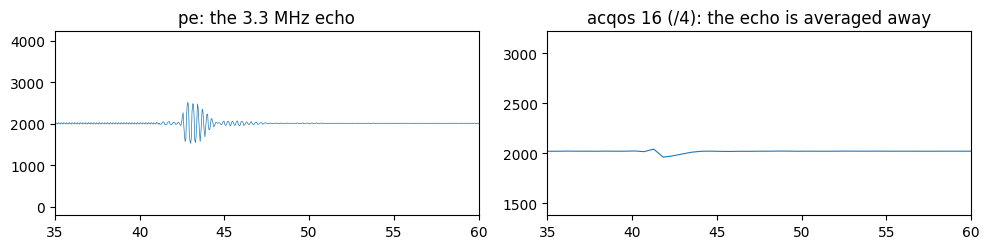

In [15]:
a = dev.acqos(16, 25, True)
p = dev.pe()
print(f"pe: {p.dt_ns:.0f} ns/sample; acqos 16: {a.dt_ns:.0f} ns/sample, window {a.fill_us:.0f} us")
fig, ax = plt.subplots(1, 2, figsize=(10, 2.6))
ax[0].plot(p.t_us, p.samples, lw=0.5); ax[0].set_xlim(35, 60); ax[0].set_title("pe: the 3.3 MHz echo")
ax[1].plot(a.t_us, a.samples / 4, lw=0.8); ax[1].set_xlim(35, 60); ax[1].set_title("acqos 16 (/4): the echo is averaged away")
plt.tight_layout(); plt.show()

## 8. Time-gain steps: `tgc`

`tgc((t_us, leg), ...)` switches the 74HC4052 gain leg of both stages at set times after the pulse, during every capture.
Here gain ×10 with a step to ×61 at 75 µs — between the first echo and the later ones. Each switch costs ~2 µs of
saturation and ~15 µs of settling (the 4052 breaks before it makes); `Capture.tgc_valid()` masks those samples.

Tgc(steps=[(75, 2)])


echo 1 (before the step): x1.1
echo 2 (in the transient): x4.7
echo 3 (after): x4.3


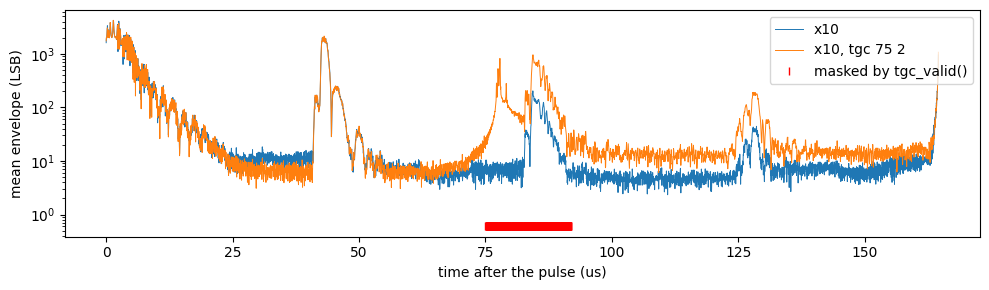

In [16]:
from minus.live import hilbert_envelope
dev.gain(0, 0, 0)
off = np.mean([hilbert_envelope(dev.pe().samples.astype(float)) for _ in range(8)], axis=0)
print(dev.tgc((75, 2)))
caps = [dev.pe() for _ in range(8)]
step = np.mean([hilbert_envelope(c.samples.astype(float)) for c in caps], axis=0)
dev.tgc("off"); dev.gain(0, 1, 0)
t = caps[0].t_us; ok = caps[0].tgc_valid()
for name, (lo, hi) in (("echo 1 (before the step)", (38, 52)), ("echo 2 (in the transient)", (80, 92)), ("echo 3 (after)", (118, 140))):
    w = (t > lo) & (t < hi); print(f"{name}: x{step[w].max() / off[w].max():.1f}")
plt.figure(figsize=(10, 3)); plt.semilogy(t, np.maximum(off, .5), lw=0.7, label="x10")
plt.semilogy(t, np.maximum(step, .5), lw=0.7, label="x10, tgc 75 2")
plt.semilogy(t[~ok], np.full((~ok).sum(), 0.6), "r|", label="masked by tgc_valid()")
plt.xlabel("time after the pulse (us)"); plt.ylabel("mean envelope (LSB)"); plt.legend(); plt.tight_layout(); plt.show()

In [17]:
dev.gain(0, 0, 0)
dev.close()